In [1]:
# ============================================================
# 06G.1 — PCA Visualizations
# Setup and Artifact Validation
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# Paths
# ------------------------------------------------------------------

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent.parent

DATA_PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PCA_ANALYSIS_DIR = DATA_PROCESSED_DIR / "pca_analysis"

FIGURE_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "pca_figures"
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------

PRIMARY_REPRESENTATION = "baseline"

N_RECORDINGS = 275
N_RETAINED_PCS = 9

# ------------------------------------------------------------------
# Load metadata
# ------------------------------------------------------------------

metadata = pd.read_csv(
    DATA_PROCESSED_DIR / "acoustic_features_recording.csv"
)

metadata["recording_id"] = (
    metadata["recording_id"].astype(str)
)

assert len(metadata) == N_RECORDINGS
assert metadata["recording_id"].is_unique

# ------------------------------------------------------------------
# Load baseline PCA scores
# ------------------------------------------------------------------

scores = np.load(
    PCA_ANALYSIS_DIR
    / "baseline_scores.npy"
)

assert scores.shape[0] == N_RECORDINGS
assert np.isfinite(scores).all()

# ------------------------------------------------------------------
# Load PCA feature names
# ------------------------------------------------------------------

with open(
    PCA_ANALYSIS_DIR
    / "baseline_feature_names.json",
    "r",
    encoding="utf-8"
) as f:

    feature_names = json.load(f)

assert len(feature_names) == scores.shape[1]

# ------------------------------------------------------------------
# Load parallel-analysis retention mask
# ------------------------------------------------------------------

retained_mask = np.asarray(
    np.load(
        PCA_ANALYSIS_DIR
        / "baseline_pa_retained.npy"
    )
).astype(bool)

retained_indices = np.where(
    retained_mask
)[0]

assert len(retained_indices) == N_RETAINED_PCS

# ------------------------------------------------------------------
# Create PCA score dataframe
# ------------------------------------------------------------------

pca_df = pd.DataFrame(
    scores[:, retained_indices],
    columns=[
        f"PC{i + 1}"
        for i in retained_indices
    ]
)

pca_df["recording_id"] = metadata[
    "recording_id"
].values

pca_df["state"] = metadata[
    "state"
].values

pca_df["species_id"] = metadata[
    "species_id"
].values

pca_df["common_name"] = metadata[
    "common_name"
].values

# ------------------------------------------------------------------
# Validation
# ------------------------------------------------------------------

assert len(pca_df) == N_RECORDINGS
assert pca_df["recording_id"].is_unique
assert pca_df["PC1"].notna().all()

print("=" * 80)
print("06G.1 — PCA VISUALIZATION SETUP")
print("=" * 80)

print("Representation:", PRIMARY_REPRESENTATION)
print("Recordings:", len(pca_df))
print("Retained PCs:", len(retained_indices))
print("States:", pca_df["state"].unique().tolist())
print("Species:", pca_df["species_id"].nunique())

print("\nPCA dataframe shape:", pca_df.shape)
print("\nFirst five rows:")
display(
    pca_df.head()
)

print("\nValidation passed.")
print("=" * 80)

06G.1 — PCA VISUALIZATION SETUP
Representation: baseline
Recordings: 275
Retained PCs: 9
States: ['AZ', 'CA', 'TX']
Species: 159

PCA dataframe shape: (275, 13)

First five rows:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,recording_id,state,species_id,common_name
0,-2.292575,-1.154328,-0.273284,-1.008739,-0.762564,0.825149,-1.837787,0.956762,0.013586,1035206,AZ,Chordeiles acutipennis,Lesser Nighthawk
1,5.474464,2.621289,-1.379148,-2.053733,0.808154,-0.473547,-0.356023,2.739642,-1.710006,1080401,AZ,Callipepla gambelii,Gambel's Quail
2,4.161407,0.808022,-1.837200,0.920360,-0.094074,-0.960238,-0.997869,-0.409167,0.684217,1080405,AZ,Callipepla squamata,Scaled Quail
3,6.841307,-4.553811,1.318361,0.451389,2.833120,1.665685,0.846128,-0.455936,0.203040,1089596,CA,Branta canadensis,Canada Goose
4,-5.804662,-0.924098,2.716870,0.043560,-1.993517,0.739720,-2.130964,0.743783,-0.368374,109164,TX,Chordeiles acutipennis,Lesser Nighthawk



Validation passed.


06G.2 — EXPLAINED VARIANCE


,PC,Explained_Variance_Ratio,Cumulative_Variance,Retained
0,1,0.209538,0.209538,True
1,2,0.121921,0.331459,True
2,3,0.067819,0.399278,True
3,4,0.060414,0.459692,True
4,5,0.054618,0.514311,True
5,6,0.048614,0.562924,True
6,7,0.042554,0.605479,True
7,8,0.038318,0.643797,True
8,9,0.033851,0.677648,True
9,10,0.028006,0.705654,False



Variance explained by PC1–PC5: 0.5143
Variance explained by PC1–PC9: 0.6776
Variance explained by first 10 PCs: 0.7057

Parallel-analysis retained PCs: 9


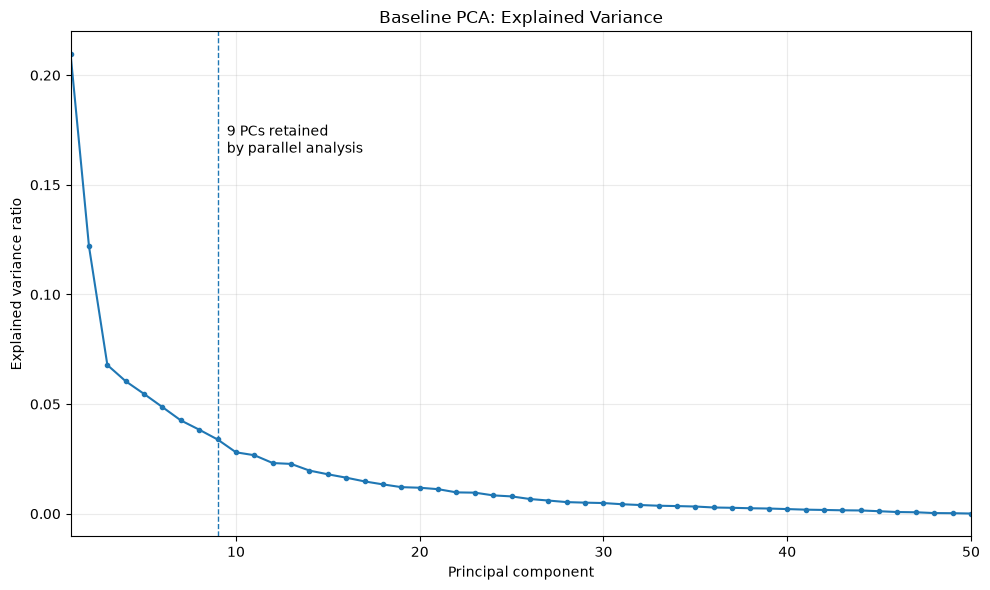


Saved:
c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\pca_figures\fig_01_pca_explained_variance.png


In [3]:
# ============================================================
# 06G.2 — Explained Variance and PCA Retention
# ============================================================

# The full baseline PCA score matrix is already loaded in `scores`
# from 06G.1. It contains all PCA dimensions, not only the retained ones.

assert scores.shape == (N_RECORDINGS, len(feature_names))
assert np.isfinite(scores).all()

# ------------------------------------------------------------------
# Derive explained variance directly from PCA scores
# ------------------------------------------------------------------

# For PCA scores, the sample variance of each component equals the
# corresponding PCA eigenvalue / explained variance.
pc_variance = np.var(
    scores,
    axis=0,
    ddof=1
)

explained_variance_ratio = (
    pc_variance / pc_variance.sum()
)

cumulative_variance = np.cumsum(
    explained_variance_ratio
)

# ------------------------------------------------------------------
# Parallel-analysis retention
# ------------------------------------------------------------------

retained_pc_count = len(retained_indices)

assert retained_pc_count == 9
assert np.isclose(
    explained_variance_ratio.sum(),
    1.0
)

# ------------------------------------------------------------------
# Summary table
# ------------------------------------------------------------------

variance_table = pd.DataFrame({
    "PC": np.arange(
        1,
        len(explained_variance_ratio) + 1
    ),
    "Explained_Variance_Ratio": explained_variance_ratio,
    "Cumulative_Variance": cumulative_variance,
    "Retained": retained_mask
})

print("=" * 80)
print("06G.2 — EXPLAINED VARIANCE")
print("=" * 80)

display(
    variance_table.head(10)
)

print(
    f"\nVariance explained by PC1–PC5: "
    f"{cumulative_variance[4]:.4f}"
)

print(
    f"Variance explained by PC1–PC9: "
    f"{cumulative_variance[8]:.4f}"
)

print(
    f"Variance explained by first 10 PCs: "
    f"{cumulative_variance[9]:.4f}"
)

print(
    f"\nParallel-analysis retained PCs: "
    f"{retained_pc_count}"
)

# ------------------------------------------------------------------
# Figure
# ------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 6)
)

pcs = np.arange(
    1,
    len(explained_variance_ratio) + 1
)

ax.plot(
    pcs,
    explained_variance_ratio,
    marker="o",
    markersize=3,
    linewidth=1.5
)

ax.set_xlabel(
    "Principal component"
)

ax.set_ylabel(
    "Explained variance ratio"
)

ax.set_title(
    "Baseline PCA: Explained Variance"
)

ax.axvline(
    retained_pc_count,
    linestyle="--",
    linewidth=1
)

ax.text(
    retained_pc_count + 0.5,
    explained_variance_ratio.max() * 0.85,
    "9 PCs retained\nby parallel analysis",
    va="top"
)

ax.set_xlim(
    1,
    len(explained_variance_ratio)
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "fig_01_pca_explained_variance.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(figure_path)
print("=" * 80)

06G.3 — PCA BY STATE

Recording counts by state:


state
AZ     75
CA    100
TX    100
Name: count, dtype: int64

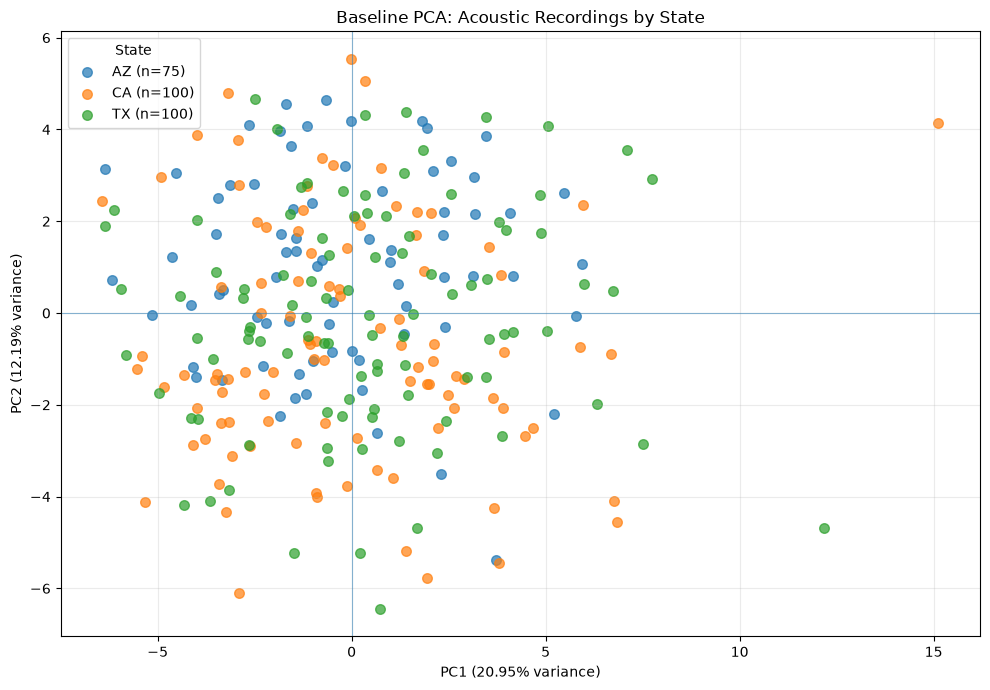


Saved:
c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\pca_figures\fig_02_pca_pc1_pc2_state.png


In [4]:
# ============================================================
# 06G.3 — PC1 × PC2 by State
# ============================================================

# ------------------------------------------------------------------
# Validate required columns
# ------------------------------------------------------------------

required_columns = [
    "PC1",
    "PC2",
    "state",
    "recording_id"
]

assert all(
    col in pca_df.columns
    for col in required_columns
)

assert len(pca_df) == 275
assert pca_df["recording_id"].is_unique
assert pca_df["PC1"].notna().all()
assert pca_df["PC2"].notna().all()

# ------------------------------------------------------------------
# State counts
# ------------------------------------------------------------------

state_counts = (
    pca_df["state"]
    .value_counts()
    .sort_index()
)

print("=" * 80)
print("06G.3 — PCA BY STATE")
print("=" * 80)

print("\nRecording counts by state:")
display(state_counts)

# ------------------------------------------------------------------
# Explained variance for axis labels
# ------------------------------------------------------------------

pc1_var = explained_variance_ratio[0]
pc2_var = explained_variance_ratio[1]

# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 7)
)

for state, group in pca_df.groupby(
    "state",
    sort=True
):

    ax.scatter(
        group["PC1"],
        group["PC2"],
        s=48,
        alpha=0.70,
        label=f"{state} (n={len(group)})"
    )

ax.axhline(
    0,
    linewidth=0.8,
    alpha=0.5
)

ax.axvline(
    0,
    linewidth=0.8,
    alpha=0.5
)

ax.set_xlabel(
    f"PC1 ({pc1_var * 100:.2f}% variance)"
)

ax.set_ylabel(
    f"PC2 ({pc2_var * 100:.2f}% variance)"
)

ax.set_title(
    "Baseline PCA: Acoustic Recordings by State"
)

ax.legend(
    title="State",
    frameon=True
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "fig_02_pca_pc1_pc2_state.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(figure_path)
print("=" * 80)

In [6]:
# ============================================================
# 06G.4 — Locate PCA Loading / Component Artifacts
# ============================================================

print("=" * 80)
print("PCA ANALYSIS ARTIFACTS")
print("=" * 80)

for path in sorted(PCA_ANALYSIS_DIR.iterdir()):

    name = path.name.lower()

    if any(
        term in name
        for term in [
            "load",
            "component",
            "pca"
        ]
    ):
        print(path.name)

print("=" * 80)

PCA ANALYSIS ARTIFACTS
baseline_components.npy
block_balanced_components.npy
distribution_aware_components.npy
ndsi_derived_excluded_components.npy
ndsi_family_excluded_components.npy
pca_analysis_metadata.json
pca_first10.csv
pca_variance_summary.csv
yeo_johnson_components.npy


06G.4 — PCA LOADINGS
Component matrix: (50, 50)
Loading matrix: (50, 50)
Maximum eigenvalue reconstruction error: 9.769962616701378e-15
Loading validation passed.

Top 10 features by absolute loading:


,PC,Rank,Feature,Loading,Absolute_Loading
0,PC1,1,mfcc_09_within_std_mean,0.877676,0.877676
1,PC1,2,mfcc_08_within_std_mean,0.869565,0.869565
2,PC1,3,mfcc_12_within_std_mean,0.868313,0.868313
3,PC1,4,mfcc_10_within_std_mean,0.859007,0.859007
4,PC1,5,mfcc_06_within_std_mean,0.835604,0.835604
5,PC1,6,mfcc_05_within_std_mean,0.832435,0.832435
6,PC1,7,mfcc_07_within_std_mean,0.830055,0.830055
7,PC1,8,mfcc_11_within_std_mean,0.827360,0.827360
8,PC1,9,mfcc_13_within_std_mean,0.800316,0.800316
9,PC1,10,mfcc_03_within_std_mean,0.692074,0.692074


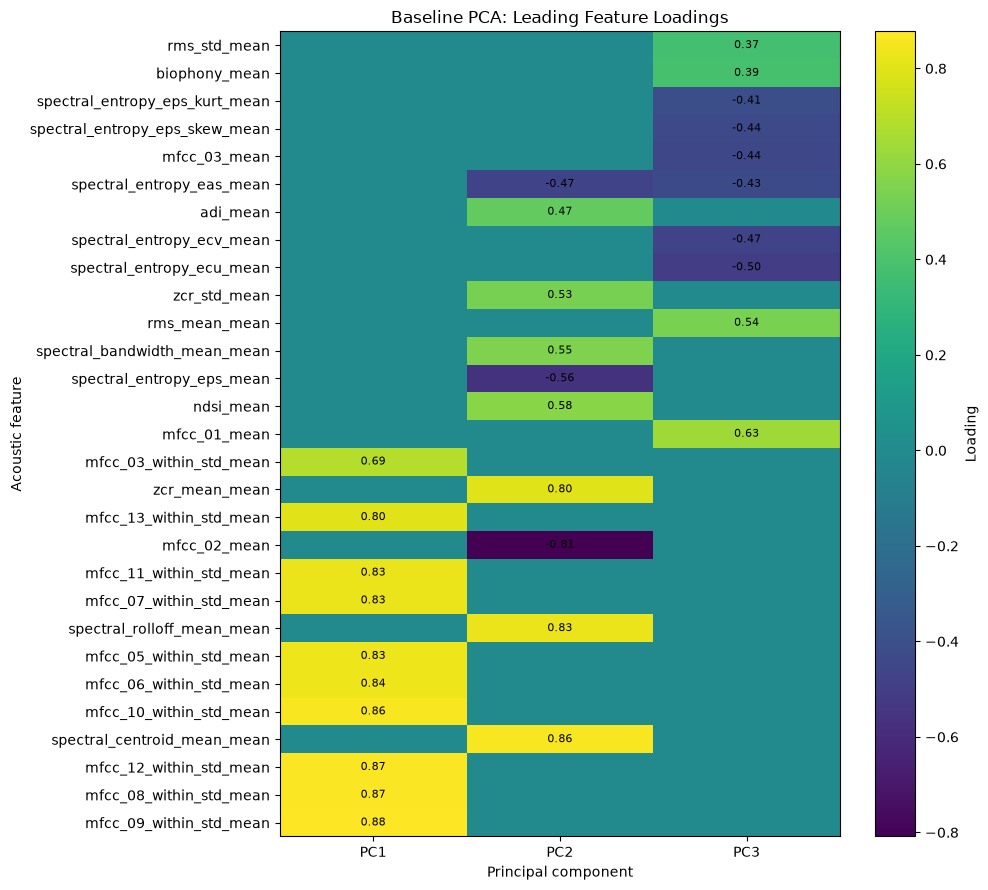


Saved:
c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\pca_figures\fig_03_pca_loadings_pc1_pc3.png


In [7]:
# ============================================================
# 06G.4 — PCA Loading Contributions
# ============================================================

# ------------------------------------------------------------------
# Load the actual PCA component directions saved by 06C/06D
# ------------------------------------------------------------------

components = np.load(
    PCA_ANALYSIS_DIR
    / "baseline_components.npy"
)

# sklearn stores:
# components.shape = (n_components, n_features)
#
# We want:
# loadings.shape = (n_features, n_components)

assert components.shape == (
    scores.shape[1],
    len(feature_names)
)

assert np.isfinite(components).all()

# ------------------------------------------------------------------
# Recover eigenvalues from the actual PCA scores
# ------------------------------------------------------------------

eigenvalues = np.var(
    scores,
    axis=0,
    ddof=1
)

assert len(eigenvalues) == components.shape[0]

# ------------------------------------------------------------------
# Conventional PCA loadings
# ------------------------------------------------------------------

loadings = (
    components.T
    * np.sqrt(eigenvalues)
)

assert loadings.shape == (
    len(feature_names),
    scores.shape[1]
)

assert np.isfinite(loadings).all()

# ------------------------------------------------------------------
# Validation
# ------------------------------------------------------------------

# Squared loadings for a given PC should sum to its eigenvalue.
loading_squared_sums = np.sum(
    loadings ** 2,
    axis=0
)

assert np.allclose(
    loading_squared_sums,
    eigenvalues,
    atol=1e-10
)

print("=" * 80)
print("06G.4 — PCA LOADINGS")
print("=" * 80)

print(
    "Component matrix:",
    components.shape
)

print(
    "Loading matrix:",
    loadings.shape
)

print(
    "Maximum eigenvalue reconstruction error:",
    np.max(
        np.abs(
            loading_squared_sums - eigenvalues
        )
    )
)

print("Loading validation passed.")

# ------------------------------------------------------------------
# Top 10 absolute loadings for PC1-PC3
# ------------------------------------------------------------------

loading_rows = []

for pc_number in [1, 2, 3]:

    pc_index = pc_number - 1

    absolute_loading = np.abs(
        loadings[:, pc_index]
    )

    top_indices = np.argsort(
        absolute_loading
    )[::-1][:10]

    for rank, feature_index in enumerate(
        top_indices,
        start=1
    ):

        loading_rows.append({
            "PC": f"PC{pc_number}",
            "Rank": rank,
            "Feature": feature_names[feature_index],
            "Loading": loadings[
                feature_index,
                pc_index
            ],
            "Absolute_Loading": absolute_loading[
                feature_index
            ]
        })

top_loading_table = pd.DataFrame(
    loading_rows
)

print("\nTop 10 features by absolute loading:")
display(
    top_loading_table
)

# ------------------------------------------------------------------
# Build plotting matrix
# ------------------------------------------------------------------

plot_features = (
    top_loading_table[
        "Feature"
    ]
    .drop_duplicates()
    .tolist()
)

loading_matrix = pd.DataFrame(
    0.0,
    index=plot_features,
    columns=["PC1", "PC2", "PC3"]
)

for _, row in top_loading_table.iterrows():

    loading_matrix.loc[
        row["Feature"],
        row["PC"]
    ] = row["Loading"]

# Put strongest features at bottom so the largest effects
# are visually prominent.
loading_matrix = loading_matrix.loc[
    loading_matrix.abs()
    .max(axis=1)
    .sort_values(
        ascending=True
    )
    .index
]

# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 9)
)

im = ax.imshow(
    loading_matrix.values,
    aspect="auto"
)

ax.set_yticks(
    np.arange(
        len(loading_matrix)
    )
)

ax.set_yticklabels(
    loading_matrix.index
)

ax.set_xticks(
    np.arange(3)
)

ax.set_xticklabels(
    ["PC1", "PC2", "PC3"]
)

ax.set_xlabel(
    "Principal component"
)

ax.set_ylabel(
    "Acoustic feature"
)

ax.set_title(
    "Baseline PCA: Leading Feature Loadings"
)

for i in range(
    loading_matrix.shape[0]
):

    for j in range(
        loading_matrix.shape[1]
    ):

        value = loading_matrix.iloc[
            i, j
        ]

        if value != 0:

            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8
            )

plt.colorbar(
    im,
    ax=ax,
    label="Loading"
)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "fig_03_pca_loadings_pc1_pc3.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(figure_path)
print("=" * 80)

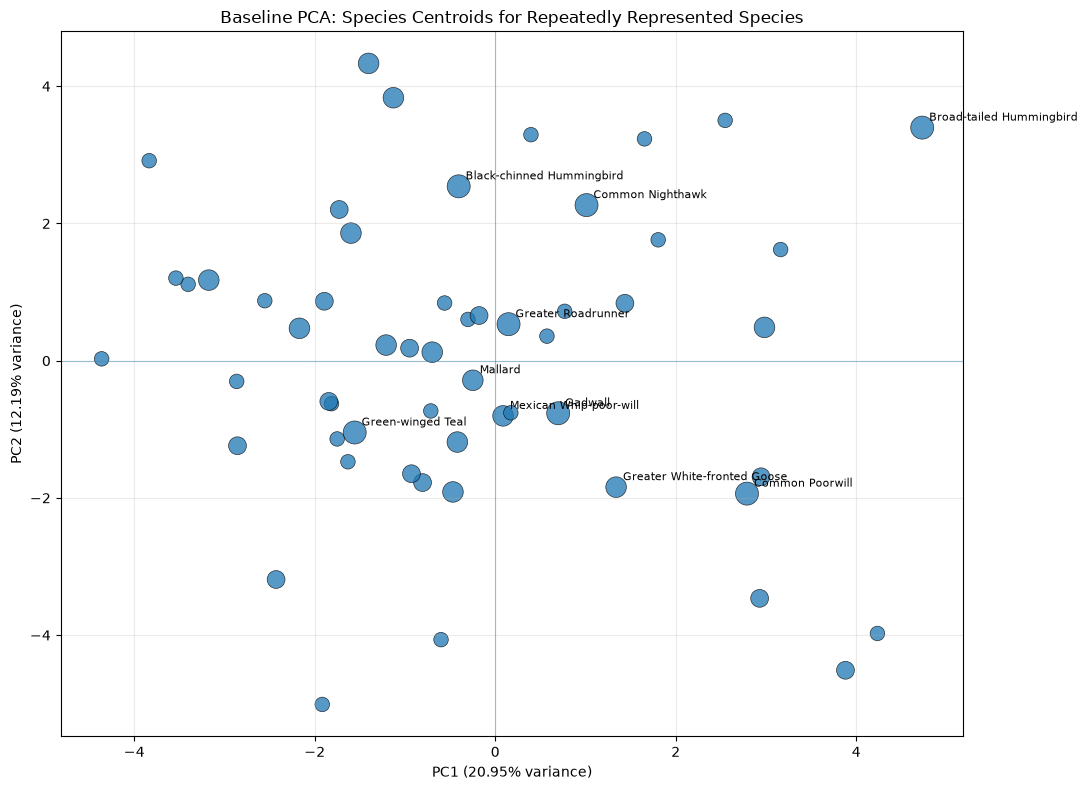

06G.5 — SPECIES CENTROIDS
Species: 56
Recordings: 172

Recording-count distribution:


n_recordings
2    23
3    13
4    13
5     7
Name: count, dtype: int64


Saved:
c:\Users\Samanwita\Downloads\from-soundscapes-to-biodiversity\data\processed\pca_figures\fig_04_pca_species_centroids.png


In [8]:
# ============================================================
# 06G.5 — Species Centroids in PCA Space
# ============================================================

# ------------------------------------------------------------------
# Use the same reproducible >=2-recording cohort as 06F
# ------------------------------------------------------------------

species_counts = (
    pca_df["species_id"]
    .value_counts()
)

eligible_species = species_counts[
    species_counts >= 2
].index

species_df = pca_df[
    pca_df["species_id"].isin(
        eligible_species
    )
].copy()

assert len(species_df) == 172
assert species_df["species_id"].nunique() == 56

# ------------------------------------------------------------------
# Calculate species centroids
# ------------------------------------------------------------------

species_centroids = (
    species_df
    .groupby(
        ["species_id", "common_name"],
        as_index=False
    )
    .agg(
        PC1=("PC1", "mean"),
        PC2=("PC2", "mean"),
        n_recordings=("recording_id", "count")
    )
)

assert len(species_centroids) == 56

# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 8)
)

scatter = ax.scatter(
    species_centroids["PC1"],
    species_centroids["PC2"],
    s=(
        species_centroids["n_recordings"]
        * 55
    ),
    alpha=0.75,
    edgecolor="black",
    linewidth=0.5
)

ax.axhline(
    0,
    linewidth=0.8,
    alpha=0.4
)

ax.axvline(
    0,
    linewidth=0.8,
    alpha=0.4
)

ax.set_xlabel(
    f"PC1 ({explained_variance_ratio[0] * 100:.2f}% variance)"
)

ax.set_ylabel(
    f"PC2 ({explained_variance_ratio[1] * 100:.2f}% variance)"
)

ax.set_title(
    "Baseline PCA: Species Centroids for Repeatedly Represented Species"
)

# ------------------------------------------------------------------
# Label only the species with the largest recording representation
# to avoid an unreadable 56-label plot.
# ------------------------------------------------------------------

label_species = (
    species_centroids
    .nlargest(
        10,
        "n_recordings"
    )
)

for _, row in label_species.iterrows():

    ax.annotate(
        row["common_name"],
        (
            row["PC1"],
            row["PC2"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.grid(
    alpha=0.25
)

plt.tight_layout()

figure_path = (
    FIGURE_DIR
    / "fig_04_pca_species_centroids.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("=" * 80)
print("06G.5 — SPECIES CENTROIDS")
print("=" * 80)

print(
    "Species:",
    species_centroids["species_id"].nunique()
)

print(
    "Recordings:",
    len(species_df)
)

print(
    "\nRecording-count distribution:"
)

display(
    species_centroids[
        "n_recordings"
    ].value_counts()
    .sort_index()
)

print("\nSaved:")
print(figure_path)
print("=" * 80)

In [9]:
# ============================================================
# 06G.6 — PCA Visualization Summary
# ============================================================

pca_summary = {
    "representation": "baseline",
    "n_recordings": int(len(pca_df)),
    "n_features": int(len(feature_names)),
    "retained_pcs": int(retained_pc_count),
    "pc1_variance": float(explained_variance_ratio[0]),
    "pc2_variance": float(explained_variance_ratio[1]),
    "pc3_variance": float(explained_variance_ratio[2]),
    "pc1_pc5_cumulative": float(cumulative_variance[4]),
    "pc1_pc9_cumulative": float(cumulative_variance[8]),
    "n_species_total": int(pca_df["species_id"].nunique()),
    "species_centroid_cohort_n_species": int(
        species_centroids["species_id"].nunique()
    ),
    "species_centroid_cohort_n_recordings": int(
        len(species_df)
    ),
}

summary_path = (
    FIGURE_DIR
    / "pca_visualization_summary.json"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        pca_summary,
        f,
        indent=2
    )

print("=" * 80)
print("06G.6 — PCA SUMMARY")
print("=" * 80)

for key, value in pca_summary.items():
    print(f"{key}: {value}")

print("\nInterpretation guardrails")
print("-" * 80)

print(
    "1. PC1 and PC2 summarize major directions of acoustic variation; "
    "they are not biodiversity indices."
)

print(
    "2. State distributions overlap substantially in PC1-PC2 space; "
    "the first two PCs do not provide clean geographic separation."
)

print(
    "3. Species centroids also overlap substantially in PC1-PC2 space; "
    "species association is supported statistically across the retained "
    "multivariate space, not by visual separation alone."
)

print(
    "4. PC1 is dominated by MFCC within-window variability, while PC2 "
    "is dominated by spectral distribution measures."
)

print(
    "5. PCA signs are arbitrary; interpretation should focus on feature "
    "magnitude and relationships rather than the sign itself."
)

print("\nSaved:")
print(summary_path)
print("=" * 80)

06G.6 — PCA SUMMARY
representation: baseline
n_recordings: 275
n_features: 50
retained_pcs: 9
pc1_variance: 0.20953786064852226
pc2_variance: 0.12192119064972032
pc3_variance: 0.06781881261914768
pc1_pc5_cumulative: 0.514310521509597
pc1_pc9_cumulative: 0.6776478657328022
n_species_total: 159
species_centroid_cohort_n_species: 56
species_centroid_cohort_n_recordings: 172

Interpretation guardrails
--------------------------------------------------------------------------------
1. PC1 and PC2 summarize major directions of acoustic variation; they are not biodiversity indices.
2. State distributions overlap substantially in PC1-PC2 space; the first two PCs do not provide clean geographic separation.
3. Species centroids also overlap substantially in PC1-PC2 space; species association is supported statistically across the retained multivariate space, not by visual separation alone.
4. PC1 is dominated by MFCC within-window variability, while PC2 is dominated by spectral distribution measu